# MobileNetV3Large — Replicare Nawaz (toate cele 5 tier-uri)

**Strict Nawaz:**
- Architecture: MobileNetV3Large + Dense(1024) + BN + Dropout + Dense(512) + BN + AlphaDropout + Dense(7)
- Total params: 4,514,951 (match Table 4)
- Loss: sparse_categorical_crossentropy + class_weight (sklearn balanced)
- Optimizer: Adam, LR=1e-3
- Augmentation: flip + rotation +/- 20° + zoom +/- 10%
- Base trainable
- 30 epochs cu EarlyStopping(patience=10) pe val_accuracy
- ReduceLROnPlateau pe val_loss


## 1. Setup

In [34]:
from google.colab import drive
drive.mount('/content/drive')
print('Drive mounted')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive mounted


In [35]:
import os
import json
import time
import random
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from scipy.ndimage import rotate as scipy_rotate
from sklearn.metrics import ( classification_report, confusion_matrix, roc_auc_score, precision_recall_fscore_support )

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print(f'TF: {tf.__version__}')
print(f'GPU: {tf.config.list_physical_devices("GPU")}')
print(f'Seed: {SEED}')

TF: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Seed: 42


In [36]:
DRIVE_BASE = Path('/content/drive/MyDrive/Thesis')
PIPELINE_DIR = DRIVE_BASE / 'pipeline_outputs'

TFRECORDS_DIR = PIPELINE_DIR / 'step4_tfrecords'   # val/, test/, tier5/
STEP2_DIR = PIPELINE_DIR / 'step2'                 # tier{N}_train.csv
OUTPUT_DIR = DRIVE_BASE / 'experiments' / 'mobilenetv3large_naive'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Hyperparameters (strict Nawaz)
IMG_SIZE = 224
NUM_CLASSES = 7
BATCH_SIZE = 32
EPOCHS = 30
LEARNING_RATE = 1e-3
DENSE1_UNITS = 1024
DENSE2_UNITS = 512
DROPOUT_RATE = 0.3
ROTATION_MAX_DEG = 20
ZOOM_RANGE = 0.1

# Paper reference values (din Nawaz Table 4 + Table 5 raportare)
PAPER_TRAINABLE_PARAMS = 1_515_527

TIERS_TO_RUN = [1, 2, 3, 4, 5]
IDX_TO_LABEL = {0: 'akiec', 1: 'bcc', 2: 'bkl', 3: 'df', 4: 'mel', 5: 'nv', 6: 'vasc'}
CLASS_NAMES = [IDX_TO_LABEL[i] for i in range(NUM_CLASSES)]

print(f'TFRecords dir:  {TFRECORDS_DIR.exists()} {TFRECORDS_DIR}')
print(f'Step2 dir:      {STEP2_DIR.exists()} {STEP2_DIR}')
print(f'Output dir:     {OUTPUT_DIR}')
print(f'Tiers to run:   {TIERS_TO_RUN}')

for split in ['val', 'test', 'tier5']:
    d = TFRECORDS_DIR / split
    if d.exists():
        shards = sorted(d.glob('*.tfrecord'))
        print(f'  {split}: {len(shards)} shard-uri')
    else:
        print(f'  [WARNING] {split}/ nu există!')

TFRecords dir:  True /content/drive/MyDrive/Thesis/pipeline_outputs/step4_tfrecords
Step2 dir:      True /content/drive/MyDrive/Thesis/pipeline_outputs/step2
Output dir:     /content/drive/MyDrive/Thesis/experiments/mobilenetv3large_naive
Tiers to run:   [1, 2, 3, 4, 5]
  val: 3 shard-uri
  test: 3 shard-uri
  tier5: 21 shard-uri


## 2. Data pipeline

Schema TFRecord (PASUL 4): `image_id, label, lesion_id, source, image_bytes`.

In [37]:
FEATURE_DESC = {
    'image_id':    tf.io.FixedLenFeature([], tf.string),
    'label':       tf.io.FixedLenFeature([], tf.int64),
    'lesion_id':   tf.io.FixedLenFeature([], tf.string),
    'source':      tf.io.FixedLenFeature([], tf.string),
    'image_bytes': tf.io.FixedLenFeature([], tf.string),
}


def parse_example(example_proto):
    return tf.io.parse_single_example(example_proto, FEATURE_DESC)


def decode_image(parsed):
    img = tf.io.decode_jpeg(parsed['image_bytes'], channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32) / 255.0   # [0, 1]
    return img, parsed['label'], parsed['lesion_id']


def get_split_files(split_name):
    pattern = str(TFRECORDS_DIR / split_name / '*.tfrecord')
    files = sorted(tf.io.gfile.glob(pattern))
    if not files:
        raise FileNotFoundError(f'No TFRecords found for split: {split_name}')
    return files


TRAIN_FILES = get_split_files('tier5')
VAL_FILES = get_split_files('val')
TEST_FILES = get_split_files('test')

print(f'Train pool (tier5): {len(TRAIN_FILES)} shards')
print(f'Val:                {len(VAL_FILES)} shards')
print(f'Test:               {len(TEST_FILES)} shards')

Train pool (tier5): 21 shards
Val:                3 shards
Test:               3 shards


In [38]:
def get_tier_lesion_ids(tier):
    if tier == 5:
        return None
    csv_path = STEP2_DIR / f'tier{tier}_train.csv'
    df = pd.read_csv(csv_path)
    return set(df['lesion_id'].astype(str).tolist())

def make_lesion_filter(allowed_ids):
    keys = tf.constant(sorted(list(allowed_ids)), dtype=tf.string)
    values = tf.ones(len(allowed_ids), dtype=tf.int32)
    table = tf.lookup.StaticHashTable(
        tf.lookup.KeyValueTensorInitializer(keys, values),
        default_value=0,
    )
    return table

for t in TIERS_TO_RUN:
    ids = get_tier_lesion_ids(t)
    if ids is None:
        print(f'Tier {t}: no filter (full tier5)')
    else:
        print(f'Tier {t}: {len(ids):,} lesion_id-uri')

Tier 1: 5,987 lesion_id-uri
Tier 2: 7,276 lesion_id-uri
Tier 3: 8,565 lesion_id-uri
Tier 4: 9,855 lesion_id-uri
Tier 5: no filter (full tier5)


In [39]:
def _random_rotate_np(image_np, max_deg):
    angle = np.random.uniform( -max_deg, max_deg )
    return scipy_rotate( image_np, angle, reshape=False, order=1, mode='reflect' ).astype(np.float32)

def augment_image(image, rotation_deg=ROTATION_MAX_DEG, zoom=ZOOM_RANGE):
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_flip_up_down(image)
    image = tf.numpy_function( func=lambda x: _random_rotate_np(x, rotation_deg), inp=[image], Tout=tf.float32 )
    image.set_shape([None, None, 3])

    zoom_factor = tf.random.uniform([], 1.0 - zoom, 1.0 + zoom)
    new_size = tf.cast(tf.cast(IMG_SIZE, tf.float32) / zoom_factor, tf.int32)
    image = tf.image.resize(image, [new_size, new_size])
    image = tf.image.resize_with_crop_or_pad(image, IMG_SIZE, IMG_SIZE)
    image = tf.clip_by_value(image, 0.0, 1.0)

    return image

def preprocess_for_model(img_01):
    """Input: float32 [0,1]. Apply MobileNetV3Large preprocessing."""
    img_255 = img_01 * 255.0
    return tf.keras.applications.mobilenet_v3.preprocess_input(img_255)

print('Augmentation + preprocessing definite')

Augmentation + preprocessing definite


In [40]:
def build_train_ds(tier):
    """Train dataset cu .repeat() — filter pe lesion_id pentru tier1-4."""
    allowed_ids = get_tier_lesion_ids(tier)

    ds = tf.data.TFRecordDataset(TRAIN_FILES, num_parallel_reads=tf.data.AUTOTUNE)
    ds = ds.map(parse_example, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(decode_image, num_parallel_calls=tf.data.AUTOTUNE)

    if allowed_ids is not None:
        table = make_lesion_filter(allowed_ids)
        ds = ds.filter( lambda img, lbl, lid: tf.equal(table.lookup(lid), 1) )

    ds = ds.map( lambda img, lbl, lid: (img, lbl), num_parallel_calls=tf.data.AUTOTUNE )
    ds = ds.repeat()
    ds = ds.shuffle(buffer_size=2000, seed=SEED, reshuffle_each_iteration=True)

    ds = ds.map( lambda img, lbl: (augment_image(img), lbl), num_parallel_calls=tf.data.AUTOTUNE )
    ds = ds.map( lambda img, lbl: (preprocess_for_model(img), lbl), num_parallel_calls=tf.data.AUTOTUNE )
    ds = ds.batch(BATCH_SIZE, drop_remainder=True)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds


def build_eval_ds(files):
    """Val/test dataset — fără shuffle, fără repeat, fără augment."""
    ds = tf.data.TFRecordDataset(files, num_parallel_reads=tf.data.AUTOTUNE)
    ds = ds.map(parse_example, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(decode_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(lambda img, lbl, lid: (img, lbl), num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map( lambda img, lbl: (preprocess_for_model(img), lbl), num_parallel_calls=tf.data.AUTOTUNE )
    ds = ds.batch(BATCH_SIZE, drop_remainder=False)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds


print('Dataset builders definite')

Dataset builders definite


In [41]:
def count_tier_samples(tier):
    """Numără sample-uri și calculează distribuția pe clase pentru un tier."""

    allowed_ids = get_tier_lesion_ids(tier)
    ds = tf.data.TFRecordDataset(TRAIN_FILES, num_parallel_reads=tf.data.AUTOTUNE)
    ds = ds.map(parse_example, num_parallel_calls=tf.data.AUTOTUNE)

    if allowed_ids is not None:
        table = make_lesion_filter(allowed_ids)
        ds = ds.filter(lambda x: tf.equal(table.lookup(x['lesion_id']), 1))

    counter = Counter()
    for ex in ds:
        counter[int(ex['label'].numpy())] += 1
    return dict(counter)


TIER_DISTRIBUTIONS = {}
for t in TIERS_TO_RUN:
    dist = count_tier_samples(t)
    TIER_DISTRIBUTIONS[t] = dist
    total = sum(dist.values())
    print(f'  Tier {t}: {total:>6,} samples — {{{", ".join(f"{IDX_TO_LABEL[k]}: {v}" for k, v in sorted(dist.items()))}}}')

val_count = sum(1 for _ in tf.data.TFRecordDataset(VAL_FILES))
test_count = sum(1 for _ in tf.data.TFRecordDataset(TEST_FILES))
print(f'\nVal:  {val_count:,} samples')
print(f'Test: {test_count:,} samples')

  Tier 1:  8,042 samples — {akiec: 268, bcc: 396, bkl: 888, df: 93, mel: 910, nv: 5378, vasc: 109}
  Tier 2: 10,996 samples — {akiec: 502, bcc: 929, bkl: 1177, df: 118, mel: 1600, nv: 6536, vasc: 134}
  Tier 3: 14,061 samples — {akiec: 720, bcc: 1495, bkl: 1504, df: 138, mel: 2296, nv: 7750, vasc: 158}
  Tier 4: 17,300 samples — {akiec: 946, bcc: 2077, bkl: 1836, df: 164, mel: 3062, nv: 9022, vasc: 193}
  Tier 5: 20,299 samples — {akiec: 1192, bcc: 2661, bkl: 2128, df: 184, mel: 3628, nv: 10297, vasc: 209}

Val:  2,519 samples
Test: 2,513 samples


In [42]:
def compute_class_weights(distribution):
    """sklearn 'balanced': total / (n_classes * count_per_class)."""
    total = sum(distribution.values())
    return {k: total / (NUM_CLASSES * v) for k, v in distribution.items()}


TIER_CLASS_WEIGHTS = {}
print('Class weights per tier:')
for t in TIERS_TO_RUN:
    cw = compute_class_weights(TIER_DISTRIBUTIONS[t])
    TIER_CLASS_WEIGHTS[t] = cw
    cw_str = ', '.join(f'{IDX_TO_LABEL[k]}: {v:.2f}' for k, v in sorted(cw.items()))
    print(f'  Tier {t}: {cw_str}')

Class weights per tier:
  Tier 1: akiec: 4.29, bcc: 2.90, bkl: 1.29, df: 12.35, mel: 1.26, nv: 0.21, vasc: 10.54
  Tier 2: akiec: 3.13, bcc: 1.69, bkl: 1.33, df: 13.31, mel: 0.98, nv: 0.24, vasc: 11.72
  Tier 3: akiec: 2.79, bcc: 1.34, bkl: 1.34, df: 14.56, mel: 0.87, nv: 0.26, vasc: 12.71
  Tier 4: akiec: 2.61, bcc: 1.19, bkl: 1.35, df: 15.07, mel: 0.81, nv: 0.27, vasc: 12.81
  Tier 5: akiec: 2.43, bcc: 1.09, bkl: 1.36, df: 15.76, mel: 0.80, nv: 0.28, vasc: 13.87


## 3. Model (strict Nawaz Table 6)

Architecture:
```
Input(224, 224, 3)
  → MobileNetV3Large (5,919,312)
  → GlobalAveragePooling2D
  → Dense(1024, relu) (1,311,744)
  → BatchNormalization (4,096)
  → Dropout(0.3)
  → Dense(512, relu) (459,110)
  → BatchNormalization (2,048)
  → Dropout(0.3)
  → Dense(7, softmax) (1,799)
Total: 4,514,951
Trainable: 1,515,527
```

In [43]:
def build_mobilenetv3large():
    inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    base = tf.keras.applications.MobileNetV3Large( include_top=False, weights='imagenet', input_shape=(IMG_SIZE, IMG_SIZE, 3) )
    base.trainable = False

    for layer in base.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False

    x = base(inputs, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)

    x = tf.keras.layers.Dense(DENSE1_UNITS, activation='relu')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Dropout(DROPOUT_RATE)(x)

    x = tf.keras.layers.Dense(DENSE2_UNITS, activation='relu')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.AlphaDropout(DROPOUT_RATE)(x)

    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)
    model = tf.keras.Model(inputs, outputs, name='MobileNetV3Large')

    total = model.count_params()
    trainable = sum(tf.size(w).numpy() for w in model.trainable_weights)
    print(f'  Total params:     {total:>12,}')
    print(f'  Trainable params: {trainable:>12,}  (BN-uri din bază înghețate)')
    print(f'  Paper Table 4:    {PAPER_TRAINABLE_PARAMS:>12,}  (cu BN trainable)')
    return model

## 4. Training utilities

In [44]:
def get_callbacks(tier_dir):
    return [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(tier_dir / 'best.keras'),
            monitor='val_accuracy', mode='max',
            save_best_only=True, verbose=1,
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor='val_accuracy', mode='max',
            patience=10, restore_best_weights=True, verbose=1,
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5,
            patience=3, min_lr=1e-7, verbose=1,
        ),
        tf.keras.callbacks.CSVLogger(
            filename=str(tier_dir / 'history.csv'), append=False,
        ),
    ]


print('Callbacks definite')

Callbacks definite


In [45]:
def evaluate_model(model, ds, label='test'):
    """Evaluate cu accuracy, precision, recall, F1, AUC, confusion matrix."""

    print(f'Evaluating on {label}...')
    y_true, y_pred, y_proba = [], [], []
    for imgs, labels in ds:
        preds = model.predict(imgs, verbose=0)
        y_proba.extend(preds)
        y_pred.extend(np.argmax(preds, axis=1))
        y_true.extend(labels.numpy())

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_proba = np.array(y_proba)

    acc = float(np.mean(y_true == y_pred))
    prec, rec, f1, _ = precision_recall_fscore_support( y_true, y_pred, average='weighted', zero_division=0 )
    macro_f1 = precision_recall_fscore_support( y_true, y_pred, average='macro', zero_division=0 )[2]

    try:
        auc = float(roc_auc_score(y_true, y_proba, multi_class='ovr', average='weighted'))
    except Exception:
        auc = float('nan')

    cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
    report = classification_report( y_true, y_pred, target_names=CLASS_NAMES, zero_division=0 )

    print(f'  Accuracy:    {acc*100:.2f}%')
    print(f'  Precision:   {prec:.4f}')
    print(f'  Recall:      {rec:.4f}')
    print(f'  Weighted F1: {f1:.4f}')
    print(f'  Macro F1:    {macro_f1:.4f}')
    print(f'  AUC (ovr):   {auc:.4f}')

    return {
        'accuracy': acc,
        'precision': float(prec),
        'recall': float(rec),
        'weighted_f1': float(f1),
        'macro_f1': float(macro_f1),
        'auc': auc,
        'confusion_matrix': cm.tolist(),
        'classification_report': report,
    }

In [46]:
def plot_results(history, cm, tier, save_path):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

    axes[0].plot(history.history['accuracy'], label='Train')
    axes[0].plot(history.history['val_accuracy'], label='Val')
    axes[0].set_title(f'Tier {tier} — Accuracy')
    axes[0].set_xlabel('Epoch')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(history.history['loss'], label='Train')
    axes[1].plot(history.history['val_loss'], label='Val')
    axes[1].set_title(f'Tier {tier} — Loss')
    axes[1].set_xlabel('Epoch')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    sns.heatmap( cm, annot=True, fmt='d', cmap='Blues', ax=axes[2], xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False )
    axes[2].set_title(f'Tier {tier} — Confusion Matrix (test)')
    axes[2].set_xlabel('Predicted')
    axes[2].set_ylabel('True')

    plt.tight_layout()
    plt.savefig(save_path, dpi=120, bbox_inches='tight')
    plt.show()

In [47]:
def train_tier(tier):

    tier_dir = OUTPUT_DIR / f'tier{tier}'
    tier_dir.mkdir(parents=True, exist_ok=True)

    results_path = tier_dir / 'results.json'
    if results_path.exists():
        print(f'\n   Tier {tier} already done, loading...')
        with open(results_path) as f:
            return json.load(f)

    print(f'\n{"#"*70}')
    print(f'# TIER {tier}')
    print(f'#   Output: {tier_dir}')
    print(f'#   Train samples: {sum(TIER_DISTRIBUTIONS[tier].values()):,}')
    print(f'#   LR={LEARNING_RATE}, batch={BATCH_SIZE}, epochs={EPOCHS}')
    print(f'{"#"*70}')

    start = time.time()
    tf.random.set_seed(SEED)
    np.random.seed(SEED)
    random.seed(SEED)

    train_ds = build_train_ds(tier)
    val_ds = build_eval_ds(VAL_FILES)
    test_ds = build_eval_ds(TEST_FILES)

    train_samples = sum(TIER_DISTRIBUTIONS[tier].values())
    steps_per_epoch = max(1, (train_samples // BATCH_SIZE) - 1)
    print(f'  Steps per epoch: {steps_per_epoch}')

    model = build_mobilenetv3large()
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE, clipnorm=1.0),
        loss='sparse_categorical_crossentropy', metrics=['accuracy']
    )

    history = model.fit(
        train_ds,
        epochs=EPOCHS,
        steps_per_epoch=steps_per_epoch,
        validation_data=val_ds,
        class_weight=TIER_CLASS_WEIGHTS[tier],
        callbacks=get_callbacks(tier_dir),
        verbose=1,
    )

    val_metrics = evaluate_model(model, val_ds, label=f'tier{tier}_val')
    test_metrics = evaluate_model(model, test_ds, label=f'tier{tier}_test')
    plot_results( history, np.array(test_metrics['confusion_matrix']), tier, save_path=tier_dir / 'plots.png' )

    elapsed_min = (time.time() - start) / 60

    results = {
        'tier': tier,
        'train_samples': train_samples,
        'epochs_run': len(history.history['loss']),
        'time_minutes': elapsed_min,
        'val': val_metrics,
        'test': test_metrics,
        'history': {k: [float(x) for x in v] for k, v in history.history.items()},
    }

    with open(results_path, 'w') as f:
        json.dump(results, f, indent=2, default=str)
    model.save(tier_dir / 'final.keras')

    print(f'\n  Tier {tier} done in {elapsed_min:.1f} min')
    print(f'  Test accuracy: {test_metrics["accuracy"]*100:.2f}%')

    del model, train_ds, val_ds, test_ds
    tf.keras.backend.clear_session()
    import gc
    gc.collect()

    return results

## 5. Run all tiers


   Tier 1 already done, loading...

######################################################################
# TIER 2
#   Output: /content/drive/MyDrive/Thesis/experiments/mobilenetv3large_naive/tier2
#   Train samples: 10,996
#   LR=0.001, batch=32, epochs=30
######################################################################
  Steps per epoch: 342
  Total params:        4,514,951
  Trainable params:    1,515,527  (BN-uri din bază înghețate)
  Paper Table 4:       1,515,527  (cu BN trainable)
Epoch 1/30
342/342 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.3618 - loss: 1.7774
Epoch 1: val_accuracy improved from None to 0.48233, saving model to /content/drive/MyDrive/Thesis/experiments/mobilenetv3large_naive/tier2/best.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/experiments/mobilenetv3large_naive/tier2/best.keras
342/342 ━━━━━━━━━━━━━━━━━━━━ 51s 102ms/step - accuracy: 0.4291 - loss: 1.6541 - val_accuracy: 0.4823 - val_loss: 2.4237 - learning_rate: 0.0010
Epoch 2/30
342/342 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.5257 - loss: 1.2510
Epoch 2: val_accuracy improved from 0.48233 to 0.48353, saving model to /content/drive/MyDrive/Thesis/experiments/mobilenetv3large_naive/tier2/best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Thesis/experiments/mobilenetv3large_naive/tier2/best.keras
342/342 ━━━━━━━━━━━━━━━━━━━━ 25s 75ms/step - accuracy: 0.5277 - loss: 1.3157 - val_accuracy: 0.4835 - val_loss: 2.3948 - learning_rate: 0.0010
Epoch 3/30
342/342 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.5608 - loss: 1.1133
Epoch 3: val_accuracy improved from 0.48353 to 0.54545, saving model to /content/drive/MyDrive/Thesis/experiments/mobilenetv3large_naive/tier2/best.ker

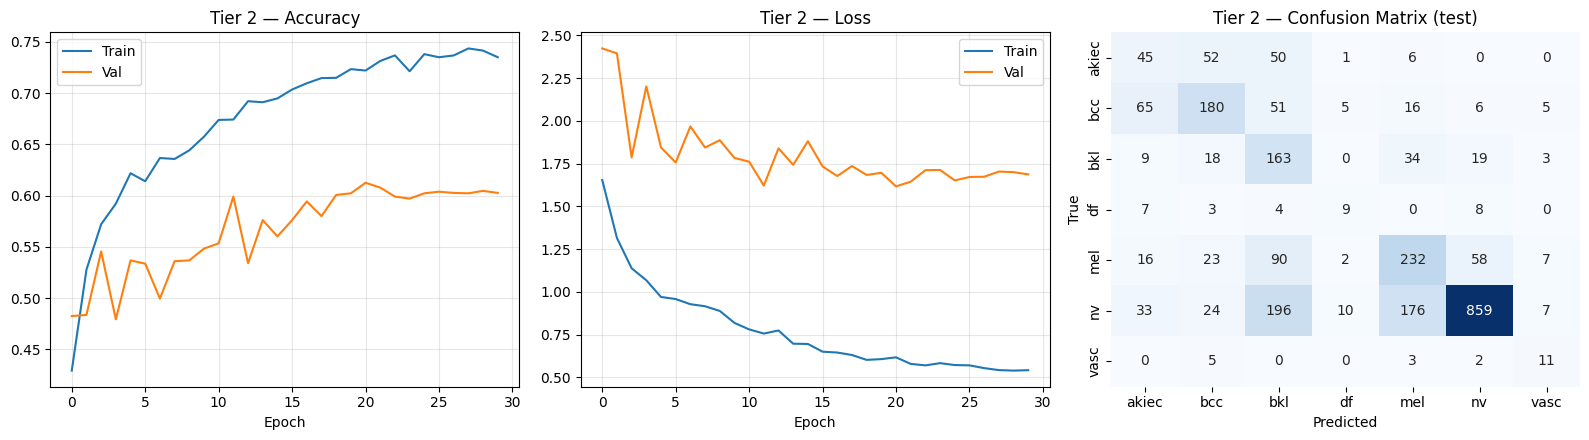


  Tier 2 done in 12.9 min
  Test accuracy: 59.65%

######################################################################
# TIER 3
#   Output: /content/drive/MyDrive/Thesis/experiments/mobilenetv3large_naive/tier3
#   Train samples: 14,061
#   LR=0.001, batch=32, epochs=30
######################################################################
  Steps per epoch: 438
  Total params:        4,514,951
  Trainable params:    1,515,527  (BN-uri din bază înghețate)
  Paper Table 4:       1,515,527  (cu BN trainable)
Epoch 1/30
438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.3854 - loss: 1.7319
Epoch 1: val_accuracy improved from None to 0.56094, saving model to /content/drive/MyDrive/Thesis/experiments/mobilenetv3large_naive/tier3/best.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/experiments/mobilenetv3large_naive/tier3/best.keras
438/438 ━━━━━━━━━━━━━━━━━━━━ 56s 93ms/step - accuracy: 0.4408 - loss: 1.6496 - val_accuracy: 0.5609 - val_loss: 1.8498 - learning_rate: 0.0010
Epoch 2/30
438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.5239 - loss: 1.2731
Epoch 2: val_accuracy did not improve from 0.56094
438/438 ━━━━━━━━━━━━━━━━━━━━ 30s 68ms/step - accuracy: 0.5323 - loss: 1.3220 - val_accuracy: 0.5014 - val_loss: 1.8408 - learning_rate: 0.0010
Epoch 3/30
438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.5653 - loss: 1.1085
Epoch 3: val_accuracy improved from 0.56094 to 0.58952, saving model to /content/drive/MyDrive/Thesis/experiments/mobilenetv3large_naive/tier3/best.keras

Epoch 3: finished saving model to /content/drive/MyDrive/Thesis/experiments/mobilenetv3large_naive/tier3/best.keras
438/438 ━━━━━━━━━━━━━━━━━━━━ 31s 70ms/step - accuracy: 0.5676 - loss: 1.1705 - val_accuracy: 0.5895 -

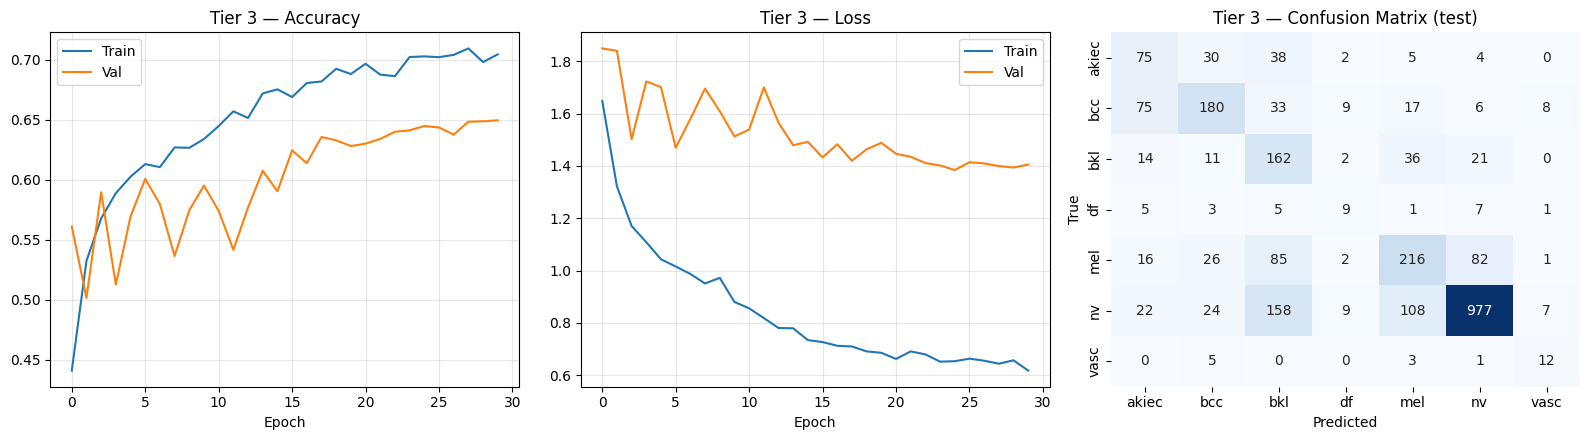


  Tier 3 done in 15.9 min
  Test accuracy: 64.90%

######################################################################
# TIER 4
#   Output: /content/drive/MyDrive/Thesis/experiments/mobilenetv3large_naive/tier4
#   Train samples: 17,300
#   LR=0.001, batch=32, epochs=30
######################################################################
  Steps per epoch: 539
  Total params:        4,514,951
  Trainable params:    1,515,527  (BN-uri din bază înghețate)
  Paper Table 4:       1,515,527  (cu BN trainable)
Epoch 1/30
539/539 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.4013 - loss: 1.6405
Epoch 1: val_accuracy improved from None to 0.56689, saving model to /content/drive/MyDrive/Thesis/experiments/mobilenetv3large_naive/tier4/best.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/experiments/mobilenetv3large_naive/tier4/best.keras
539/539 ━━━━━━━━━━━━━━━━━━━━ 64s 89ms/step - accuracy: 0.4554 - loss: 1.5924 - val_accuracy: 0.5669 - val_loss: 1.7996 - learning_rate: 0.0010
Epoch 2/30
539/539 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.5394 - loss: 1.2612
Epoch 2: val_accuracy did not improve from 0.56689
539/539 ━━━━━━━━━━━━━━━━━━━━ 37s 69ms/step - accuracy: 0.5366 - loss: 1.3023 - val_accuracy: 0.5617 - val_loss: 1.7480 - learning_rate: 0.0010
Epoch 3/30
539/539 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.5743 - loss: 1.1193
Epoch 3: val_accuracy improved from 0.56689 to 0.60183, saving model to /content/drive/MyDrive/Thesis/experiments/mobilenetv3large_naive/tier4/best.keras

Epoch 3: finished saving model to /content/drive/MyDrive/Thesis/experiments/mobilenetv3large_naive/tier4/best.keras
539/539 ━━━━━━━━━━━━━━━━━━━━ 37s 69ms/step - accuracy: 0.5697 - loss: 1.1679 - val_accuracy: 0.6018 -

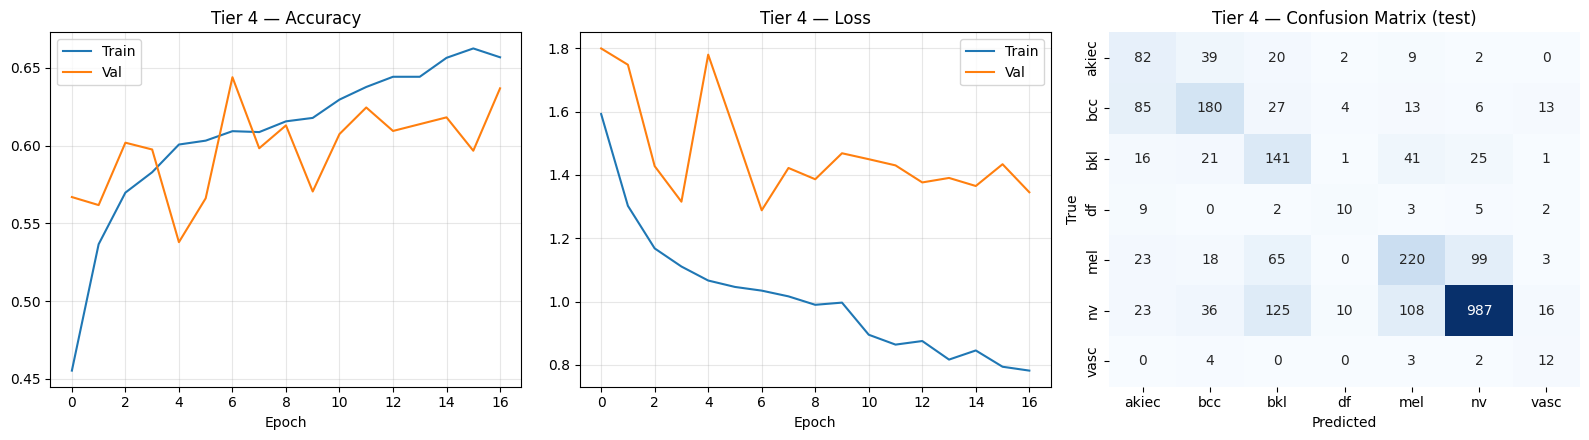


  Tier 4 done in 12.1 min
  Test accuracy: 64.94%

######################################################################
# TIER 5
#   Output: /content/drive/MyDrive/Thesis/experiments/mobilenetv3large_naive/tier5
#   Train samples: 20,299
#   LR=0.001, batch=32, epochs=30
######################################################################
  Steps per epoch: 633
  Total params:        4,514,951
  Trainable params:    1,515,527  (BN-uri din bază înghețate)
  Paper Table 4:       1,515,527  (cu BN trainable)
Epoch 1/30
633/633 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.4122 - loss: 1.6286
Epoch 1: val_accuracy improved from None to 0.56411, saving model to /content/drive/MyDrive/Thesis/experiments/mobilenetv3large_naive/tier5/best.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/experiments/mobilenetv3large_naive/tier5/best.keras
633/633 ━━━━━━━━━━━━━━━━━━━━ 70s 85ms/step - accuracy: 0.4589 - loss: 1.5948 - val_accuracy: 0.5641 - val_loss: 1.8056 - learning_rate: 0.0010
Epoch 2/30
632/633 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.5374 - loss: 1.2163
Epoch 2: val_accuracy did not improve from 0.56411
633/633 ━━━━━━━━━━━━━━━━━━━━ 43s 68ms/step - accuracy: 0.5350 - loss: 1.3058 - val_accuracy: 0.5570 - val_loss: 1.6560 - learning_rate: 0.0010
Epoch 3/30
633/633 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.5816 - loss: 1.0106
Epoch 3: val_accuracy improved from 0.56411 to 0.59309, saving model to /content/drive/MyDrive/Thesis/experiments/mobilenetv3large_naive/tier5/best.keras

Epoch 3: finished saving model to /content/drive/MyDrive/Thesis/experiments/mobilenetv3large_naive/tier5/best.keras
633/633 ━━━━━━━━━━━━━━━━━━━━ 44s 69ms/step - accuracy: 0.5740 - loss: 1.1581 - val_accuracy: 0.5931 -

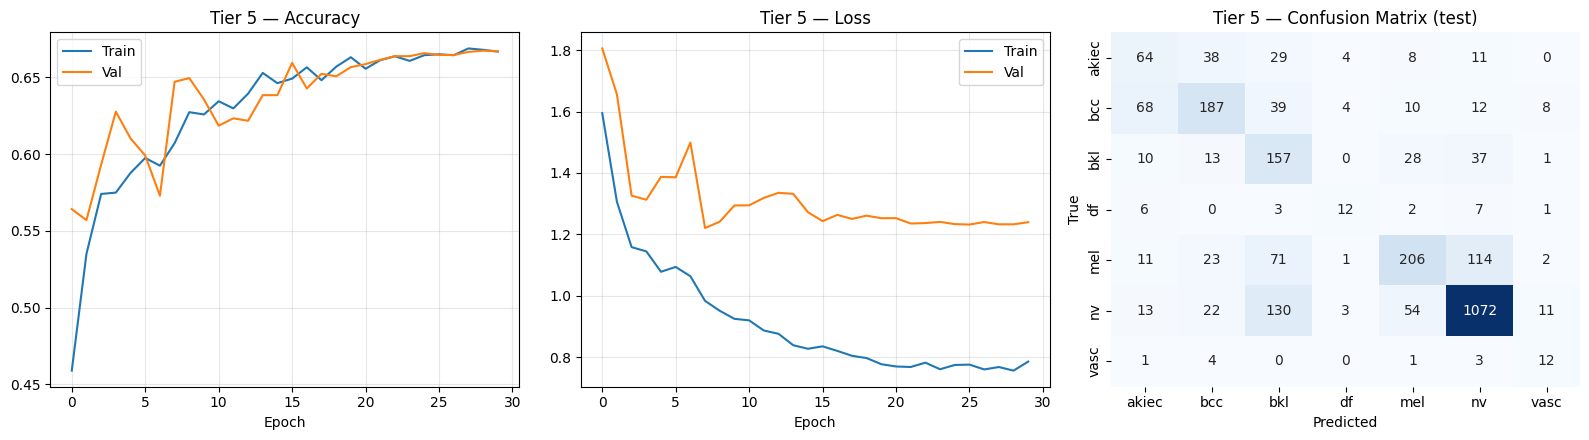


  Tier 5 done in 23.0 min
  Test accuracy: 68.05%

ALL TIERS COMPLETE


In [48]:
all_results = {}

for tier in TIERS_TO_RUN:
    all_results[tier] = train_tier(tier)

print('\n' + '=' * 70)
print('ALL TIERS COMPLETE')
print('=' * 70)

## 6. Summary

In [49]:
rows = []
for tier, res in sorted(all_results.items()):
    rows.append({
        'tier': tier,
        'train_samples': res['train_samples'],
        'epochs': res['epochs_run'],
        'val_acc': res['val']['accuracy'] * 100,
        'val_macro_f1': res['val']['macro_f1'],
        'test_acc': res['test']['accuracy'] * 100,
        'test_macro_f1': res['test']['macro_f1'],
        'test_weighted_f1': res['test']['weighted_f1'],
        'test_auc': res['test']['auc'],
        'time_min': res['time_minutes'],
    })

summary_df = pd.DataFrame(rows)
print(summary_df.to_string(index=False, float_format=lambda x: f'{x:.3f}'))

summary_df.to_csv(OUTPUT_DIR / 'summary.csv', index=False)
print(f'\nSummary saved to: {OUTPUT_DIR / "summary.csv"}')

 tier  train_samples  epochs  val_acc  val_macro_f1  test_acc  test_macro_f1  test_weighted_f1  test_auc  time_min
    1           8042      14   42.914         0.350    41.186          0.308             0.461     0.803     5.767
    2          10996      30   61.254         0.522    59.650          0.464             0.622     0.874    12.864
    3          14061      30   64.946         0.529    64.903          0.508             0.667     0.887    15.939
    4          17300      17   64.391         0.488    64.942          0.498             0.665     0.885    12.116
    5          20299      30   66.733         0.519    68.046          0.532             0.688     0.892    23.015

Summary saved to: /content/drive/MyDrive/Thesis/experiments/mobilenetv3large_naive/summary.csv


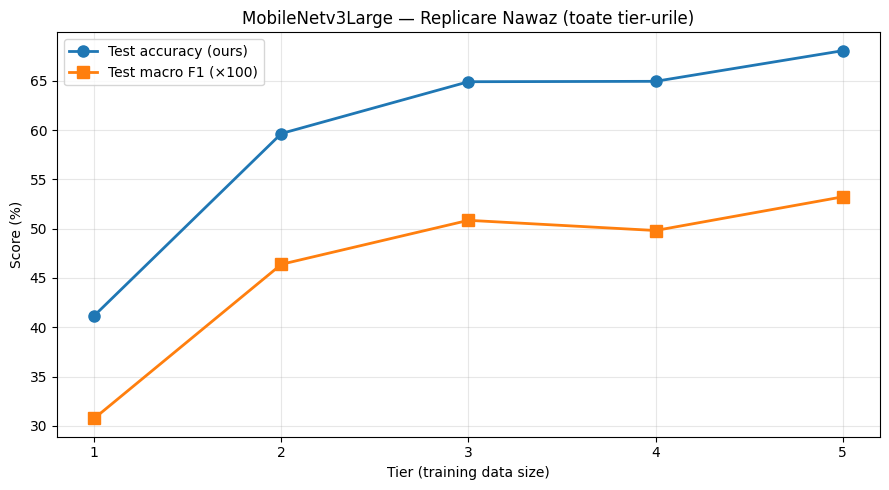

In [50]:
fig, ax = plt.subplots(figsize=(9, 5))

tiers_x = [r['tier'] for r in rows]
test_acc = [r['test_acc'] for r in rows]
macro_f1 = [r['test_macro_f1'] * 100 for r in rows]

ax.plot(tiers_x, test_acc, 'o-', label='Test accuracy (ours)', linewidth=2, markersize=8)
ax.plot(tiers_x, macro_f1, 's-', label='Test macro F1 (×100)', linewidth=2, markersize=8)
ax.set_xlabel('Tier (training data size)')
ax.set_ylabel('Score (%)')
ax.set_title('MobileNetv3Large — Replicare Nawaz (toate tier-urile)')
ax.set_xticks(tiers_x)
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'tiers_summary.png', dpi=120, bbox_inches='tight')
plt.show()

In [51]:
for tier in sorted(all_results.keys()):
    print(f'\n{"="*70}\nTier {tier} — TEST classification report\n{"="*70}')
    print(all_results[tier]['test']['classification_report'])


Tier 1 — TEST classification report
              precision    recall  f1-score   support

       akiec       0.24      0.14      0.17       154
         bcc       0.53      0.12      0.20       328
         bkl       0.16      0.74      0.26       246
          df       0.06      0.39      0.10        31
         mel       0.50      0.27      0.35       428
          nv       0.91      0.50      0.64      1305
        vasc       0.34      0.57      0.43        21

    accuracy                           0.41      2513
   macro avg       0.39      0.39      0.31      2513
weighted avg       0.66      0.41      0.46      2513


Tier 2 — TEST classification report
              precision    recall  f1-score   support

       akiec       0.26      0.29      0.27       154
         bcc       0.59      0.55      0.57       328
         bkl       0.29      0.66      0.41       246
          df       0.33      0.29      0.31        31
         mel       0.50      0.54      0.52       428
    